In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

# String

In [32]:
# wget https://stringdb-downloads.org/download/protein.links.v12.0/9606.protein.links.v12.0.txt.gz
# unzip 9606.protein.links.v12.0.txt.gz
df = pd.read_csv("/Users/peidli/work/data/SYMPHONY/StringDB_PPI_9606.protein.links.v12.0.txt", sep=" ")
df.rename(columns={"combined_score": "string_interaction_combined_score"}, inplace=True)
df.sort_values(by="string_interaction_combined_score", ascending=False, inplace=True)
df['protein1'] = [x.split('.')[1] for x in df.protein1]
df['protein2'] = [x.split('.')[1] for x in df.protein2]

In [33]:
# map proteins to genes
mart_mapping = pd.read_csv("../resources/mart_export.txt.gz", sep="\t")
df = df.merge(mart_mapping, left_on="protein1", right_on="Protein stable ID", how="left")
df = df.merge(mart_mapping, left_on="protein2", right_on="Protein stable ID", how="left")
# Rename the columns 'Gene stable ID_x', 'Protein stable ID_x', 'Gene name_x', 'Gene stable ID_y', 'Protein stable ID_y', 'Gene name_y'
df.rename({'Gene stable ID_x': 'gene_id_1', 
           'Gene name_x': 'gene_1', 
           'Gene stable ID_y': 'gene_id_2', 
           'Gene name_y': 'gene_2'}, 
          axis=1, inplace=True)
df.drop(['Protein stable ID_x', 'Protein stable ID_y'], axis=1, inplace=True)
df = df[df.columns.sort_values()]

file = "../results/tables/stringdb_ppi.tsv.gz"
if not Path(file).exists():
    df.to_csv(file, sep="\t", index=False, compression="gzip")

In [36]:
df

,gene_1,gene_2,gene_id_1,gene_id_2,protein1,protein2,string_interaction_combined_score
0,ELOC,CUL5,ENSG00000154582,ENSG00000166266,ENSP00000478121,ENSP00000376808,999
1,NDUFV3,NDUFS4,ENSG00000160194,ENSG00000164258,ENSP00000346196,ENSP00000296684,999
2,NDUFV3,NDUFV1,ENSG00000160194,ENSG00000167792,ENSP00000346196,ENSP00000497587,999
3,CRCP,POLR3B,ENSG00000241258,ENSG00000013503,ENSP00000378736,ENSP00000228347,999
4,PHF21A,RCOR1,ENSG00000135365,ENSG00000089902,ENSP00000398824,ENSP00000262241,999
...,...,...,...,...,...,...,...
13737061,ZNF335,JUND,ENSG00000198026,ENSG00000130522,ENSP00000325326,ENSP00000252818,150
13737062,DHX35,TANGO6,ENSG00000101452,ENSG00000103047,ENSP00000252011,ENSP00000261778,150
13737063,MEIS1,ZNF382,ENSG00000143995,ENSG00000161298,ENSP00000272369,ENSP00000292928,150
13737064,KIAA1671,TUBB1,ENSG00000197077,ENSG00000101162,ENSP00000351207,ENSP00000217133,150


# Synleth

In [23]:
# wget https://synlethdb.sist.shanghaitech.edu.cn/static/download/SL/Human_SL.csv
df = pd.read_csv("/Users/peidli/work/data/SYMPHONY/SynlethDB_Human_SL.csv")
df.drop(['n1.identifier', 'n2.identifier'], axis=1, inplace=True)
df.rename(columns={'n1.name': 'gene1', 'n2.name': 'gene2', 
                   'r.cell_line': 'cell_line',
                   'r.pubmed_id': 'pubmed_id',
                   'r.source': 'source',
                   'r.statistic_score': 'SynlethDB_score',
                   }, inplace=True)

In [24]:
is_lung = ['lung' in str(x).lower() for x in df.cell_line]
sdf = df[is_lung].copy().sort_values('SynlethDB_score', ascending=False)

In [30]:
sdf.head(10)

,gene1,gene2,cell_line,pubmed_id,source,SynlethDB_score
196,KRAS,VDAC1,Human lung cancer,17568748,Synlethality,0.8550
4261,DHX8,KRAS,"Human non-small cell lung-cancer, Lung Adenoca...",19490893,Synlethality,0.8550
14025,MAPK1,MYC,HMEC;adenocarcinoma;Lung cancer_D000230;D008175,22157079;21430111;21543344,GenomeRNAi;Text Mining,0.8500
22757,EGFR,PARP1,"A549,PC3,MDA468;non-small cell lung cancer;bre...",3965078;24954871;23071597;23564760,Decipher;Text Mining,0.8336
128,KRAS,USP39,"Human non-small cell lung-cancer, Lung Adenoca...",19490893,Synlethality;GenomeRNAi,0.8150
9694,CDK2,CDK6,"A549,PC3,MDA468;non-small cell lung carcinoma_...",3965078;20609353,Decipher;Text Mining,0.6385
9717,CDK2,CDK4,"A549,PC3,MDA468;non-small cell lung carcinoma_...",3965078;20609353,Decipher;Text Mining,0.6355
27735,CDK4,PARP1,"A549,PC3,MDA468;lung adenocarcinoma_C538231",3965078;23792647,Decipher;Text Mining,0.6355
27755,CDK4,CDK6,"A549,PC3,MDA468;non-small cell lung carcinoma_...",3965078;20609353,Decipher;Text Mining,0.6175
3025,AKT1,MAPK8,castration-resistant prostate cancer;lung canc...,23566222;23824739,Text Mining,0.5600


In [29]:
len(sdf)

127

In [55]:
sdf.to_csv('../results/tables/SynlethDB_Human_SL_lung.csv', index=False)

# DepMap

# DrugComb

In [26]:
# https://drugcomb.fimm.fi/jing/summary_v_1_5.csv

In [27]:
df = pd.read_csv('/Users/peidli/work/data/SYMPHONY/DrugComb_summary_v_1_5.csv', index_col=0)
df = df[df.tissue_name == 'lung']
df.drop(['tissue_name'], axis=1, inplace=True)

In [28]:
df.head()

,drug_row,drug_col,cell_line_name,study_name,conc_row_unit,conc_col_unit,ic50_row,ic50_col,ri_row,ri_col,...,S_mean,S_max,synergy_zip,synergy_loewe,synergy_hsa,synergy_bliss,drug_row_clinical_phase,drug_col_clinical_phase,drug_row_target_name,drug_col_target_name
block_id,,,,,,,,,,,,,,,,,,,,,
6901,5-Fluorouracil,Veliparib,A427,ONEIL,uM,uM,10.0,2.108345,25.762,13.359,...,33.2710,27.0695,-2.172063,-5.829946,2.732815,-4.297353,4,3,Prelamin-A/C; Survival motor neuron protein; T...,Poly [ADP-ribose] polymerase-1; Poly [ADP-ribo...
6902,5-Fluorouracil,Veliparib,A427,ONEIL,uM,uM,10.0,2.108345,25.762,13.359,...,30.4080,24.2065,-0.846962,-4.609759,3.953003,-3.077166,4,3,Prelamin-A/C; Survival motor neuron protein; T...,Poly [ADP-ribose] polymerase-1; Poly [ADP-ribo...
6903,5-Fluorouracil,Veliparib,A427,ONEIL,uM,uM,10.0,2.108345,25.762,13.359,...,38.2235,32.0220,3.409065,-0.532071,8.030690,1.000522,4,3,Prelamin-A/C; Survival motor neuron protein; T...,Poly [ADP-ribose] polymerase-1; Poly [ADP-ribo...
6904,5-Fluorouracil,Veliparib,A427,ONEIL,uM,uM,10.0,2.108345,25.762,13.359,...,31.0245,24.8230,-0.997590,-4.800884,3.761878,-3.268291,4,3,Prelamin-A/C; Survival motor neuron protein; T...,Poly [ADP-ribose] polymerase-1; Poly [ADP-ribo...
6905,5-Fluorouracil,MK-1775,A427,ONEIL,uM,uM,10.0,0.221084,25.762,35.468,...,44.1145,39.2615,5.964867,3.184023,11.688652,5.489243,4,2,Prelamin-A/C; Survival motor neuron protein; T...,Serine/threonine-protein kinase TBK1; Protein ...


# Gene Expression

## Tumor single-cell datasets

In [28]:
import scanpy as sc
data_path = Path('/Users/peidli/work/data/Lung_Cancer/')

In [29]:
# Load Data
adata = sc.read(data_path / 'Bischoff_2021_lung_cancer_patient_data/Bischoff_2021_lung_cancer_patient_data_raw.h5')

In [30]:
sc.pp.filter_cells(adata, min_counts=500)
sc.pp.filter_genes(adata, min_counts=3)

In [31]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [32]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

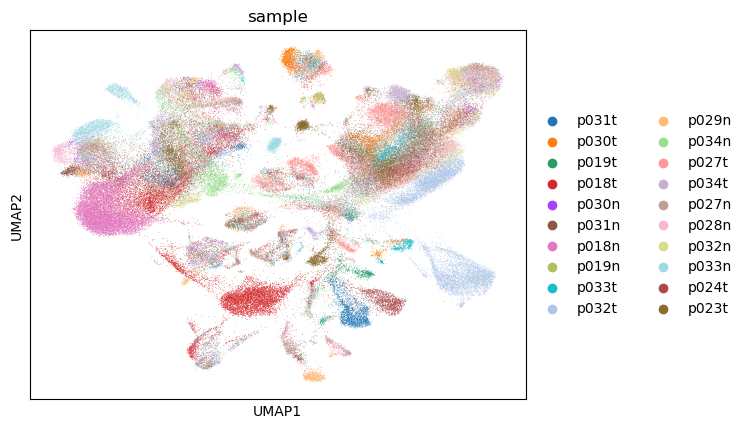

In [34]:
sc.pl.umap(adata, color='sample')

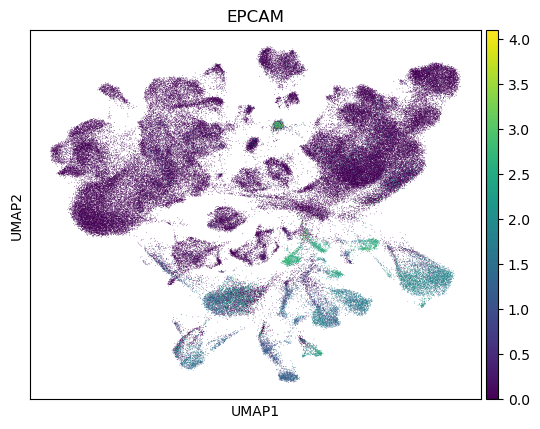

In [35]:
sc.pl.umap(adata, color='EPCAM')

In [33]:
adata

AnnData object with n_obs × n_vars = 133736 × 28226
    obs: 'sample', 'copy_number_status', 'ncounts', 'ngenes', 'percent_mito', 'percent_ribo', 'percent_hemo', 'n_counts'
    var: 'ncounts', 'ncells', 'n_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'